# Consumer Complaint Volume Forecasting Prototype
**AnalystLab Africa · Machine Learning Track · Week 4**

**Author:** Umar Muhammad  |  **Data:** CFPB consumer complaints about Bank of America, 62,516 records, 1 May 2017 – 28 Aug 2023

---
## 0. Business understanding
Stakeholders need a dependable way to monitor consumer complaints and to anticipate workload. This notebook builds and tests a **monthly complaint-volume forecasting prototype**, the Machine Learning deliverable of the shared Consumer Complaint Intelligence project.

**Prediction problem.** *Given the monthly complaint counts observed up to a month, forecast the number of complaints the CFPB will receive in each of the next 1 – 6 months.* The target is the **count of complaints by `Date submitted`** (the date the CFPB received the complaint).

**What this project does not claim.**
* A complaint is a consumer-reported issue. It does **not** prove misconduct or a regulatory breach.
* A forecast of complaint *volume* says nothing about the company's actual performance, and is not a prediction of misconduct.
* Recorded company responses are not proof that a complaint was resolved satisfactorily.

**Workflow:** inspect and validate the data → define shared KPIs → explore trends → define target, features and validation → baselines and models → rolling-origin backtest → error analysis → product-level forecasts → forecast the future → save the workflow.

## 1. Setup

In [1]:
import json, textwrap, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import joblib

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import STL
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor

warnings.simplefilter("ignore")        # statsmodels is chatty on small samples; set AFTER importing it
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold"})
SEED = 42
RAW, OUT, IMG, REP, MOD = Path("../data/raw"), Path("../data/processed"), Path("../images"), Path("../reports"), Path("../models")
PAL = sns.color_palette("deep")
results = {}

def save_fig(name):
    plt.tight_layout()
    plt.savefig(IMG / name, dpi=150, bbox_inches="tight")
    plt.show()

## 2. Data inspection, validation and cleaning
The original workbook is kept untouched in `data/raw/`. Everything below works on an in-memory copy, so the cleaning is fully reproducible.

### 2.1 Structure and types

In [2]:
raw = pd.read_excel(RAW / "Consumer_Complaints.xlsx", sheet_name="Data")
dictionary = pd.read_csv(RAW / "ConsumerComplaints_DataDictionary.csv", encoding="utf-8-sig")
print(f"Rows: {raw.shape[0]:,} | columns: {raw.shape[1]}")
print(raw.dtypes.to_string())
raw.head(5)

Rows: 62,516 | columns: 12
Complaint ID                             int64
Submitted via                              str
Date submitted                  datetime64[us]
Date received                   datetime64[us]
State                                      str
Product                                    str
Sub-product                                str
Issue                                      str
Sub-issue                                  str
Company public response                    str
Company response to consumer               str
Timely response?                           str


,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an exis...,NaN,Company has responded to the consumer and the ...,Closed with explanation,Yes
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money ser...",Refund anticipation check,Lost or stolen check,NaN,Company has responded to the consumer and the ...,Closed with monetary relief,Yes
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the ...,Closed with explanation,Yes
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a ...",NaN,In progress,NaN
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Company has responded to the consumer and the ...,Closed with explanation,Yes


In [3]:
pd.set_option("display.max_colwidth", 120)
dictionary

,Field,Description
0,Complaint ID,The unique identification number for a complaint
1,Submitted via,How the complaint was submitted to the CFPB
2,Date submitted,The date the CFPB received the complaint
3,Date received,The date the CFPB sent the complaint to the company
4,State,The state of the mailing address provided by the consumer
5,Product,The type of product the consumer identified in the complaint
6,Sub-product,The type of sub-product the consumer identified in the complaint (not all Products have Sub-products)
7,Issue,The issue the consumer identified in the complaint (possible values are dependent on Product)
8,Sub-issue,"The sub-issue the consumer identified in the complaint (oossible values are dependent on Product and Issue, and not ..."
9,Company public response,"The company's optional, public-facing response to a consumer's complaint. Companies can choose to select a response ..."


### 2.2 Key, duplicates and missing values

In [4]:
df = raw.copy()
df.columns = [c.lower().replace(" ", "_").replace("?", "").replace("-", "_") for c in df.columns]
print("Complaint ID unique (candidate primary key):", df.complaint_id.is_unique)
print("Fully duplicated rows:", int(df.duplicated().sum()))
print("Rows identical in every field except the ID:", int(df.drop(columns="complaint_id").duplicated().sum()))
miss = df.isna().sum().rename("missing").to_frame(); miss["pct"] = (miss.missing / len(df) * 100).round(2)
miss[miss.missing > 0]

Complaint ID unique (candidate primary key): True
Fully duplicated rows: 0
Rows identical in every field except the ID: 1494


,missing,pct
sub_product,7,0.01
sub_issue,10858,17.37
company_public_response,2175,3.48
timely_response,1494,2.39


In [5]:
print("Company response vs timely-response flag:")
print(pd.crosstab(df.company_response_to_consumer, df.timely_response.fillna("(blank)")).to_string())
print("\nCompany response vs public response missing?")
print(pd.crosstab(df.company_response_to_consumer, df.company_public_response.isna().rename("public_response_missing")).to_string())

Company response vs timely-response flag:


timely_response                  (blank)    No    Yes
company_response_to_consumer                         
Closed                                 0     8      0
Closed with explanation                0  1527  39517
Closed with monetary relief            0   690  14007
Closed with non-monetary relief        0   178   5095
In progress                         1494     0      0

Company response vs public response missing?
public_response_missing          False  True 
company_response_to_consumer                 
Closed                               0      8
Closed with explanation          40575    469
Closed with monetary relief      14533    164
Closed with non-monetary relief   5233     40
In progress                          0   1494


**What the missing values mean** (as the brief requires, each is treated according to its meaning, not blanket-filled):

| Field | Missing | Meaning, verified above | Treatment |
|---|---|---|---|
| `timely_response` | 1,494 | **All and only** the complaints marked *In progress* (no outcome yet) | Kept as "Not yet determined"; **never counted as No**; excluded from the timely-response denominator and reported separately |
| `company_public_response` | 2,175 | 1,494 are *In progress*; 681 are closed complaints with no public response recorded | Labelled "No public response recorded" |
| `sub_issue` | 10,858 | The reported issue has no sub-issue (not every issue has one) | Labelled "Not specified" |
| `sub_product` | 7 | Seven *Checking or savings account* complaints without a sub-product | Labelled "Not specified" |

**Duplicates.** The Complaint ID is unique and no row is duplicated. 1,494 rows are identical to another row in every field *except* the ID. Different IDs mean different complaints, so they are **kept** and noted. (The count equals the number of In-progress rows by coincidence of identical attributes; it does not change any monthly count materially.)

### 2.3 Date validation and the CFPB forwarding interval
`Date submitted` = when the CFPB received the complaint. `Date received` = when the CFPB sent it to the company. Their difference is the **CFPB complaint-forwarding interval**, *not* the company's response or resolution time.

In [6]:
df["forward_interval_days"] = (df.date_received - df.date_submitted).dt.days
print("Date columns are datetimes:", df.date_submitted.dtype, df.date_received.dtype)
print("Received before submitted (invalid):", int((df.forward_interval_days < 0).sum()))
print("Date submitted range:", df.date_submitted.min().date(), "->", df.date_submitted.max().date())
print("Date received  range:", df.date_received.min().date(), "->", df.date_received.max().date())
iv = df.forward_interval_days
print(f"\nForwarding interval: mean {iv.mean():.2f} d | median {iv.median():.0f} d | same-day {iv.eq(0).mean() * 100:.1f}% | "
      f">7 d: {int((iv > 7).sum())} | >30 d: {int((iv > 30).sum())} | max {iv.max()} d")
results["iv_mean"], results["iv_median"] = round(float(iv.mean()), 2), float(iv.median())
results["iv_same_day_pct"] = round(float(iv.eq(0).mean() * 100), 1); results["iv_gt30"] = int((iv > 30).sum()); results["iv_max"] = int(iv.max())

Date columns are datetimes: datetime64[us] datetime64[us]
Received before submitted (invalid): 0
Date submitted range: 2017-05-01 -> 2023-08-28
Date received  range: 2017-05-01 -> 2023-08-28

Forwarding interval: mean 1.22 d | median 0 d | same-day 79.4% | >7 d: 2443 | >30 d: 435 | max 275 d


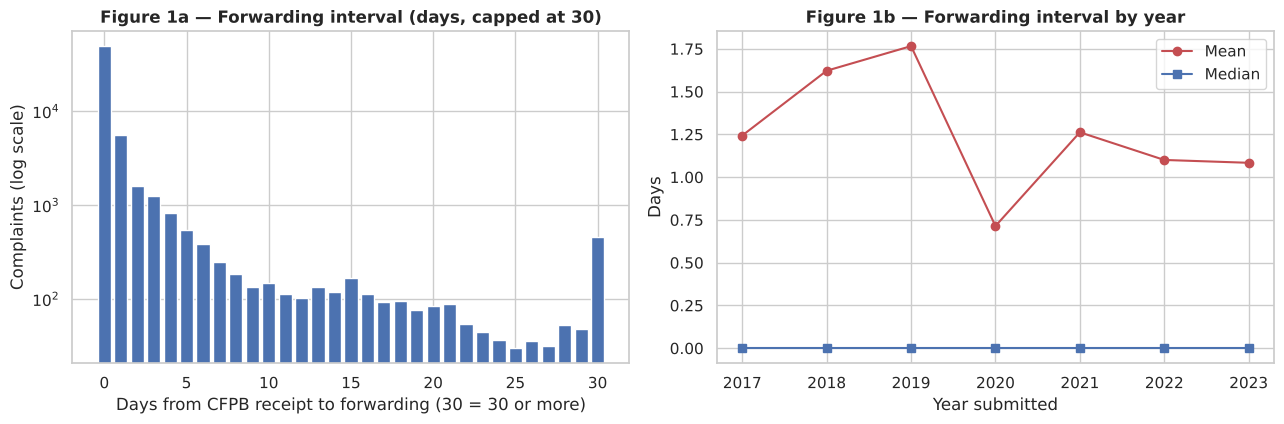

In [7]:
df["year"], df["month"] = df.date_submitted.dt.year, df.date_submitted.dt.month
df["quarter"] = df.date_submitted.dt.quarter
df["year_month"] = df.date_submitted.dt.to_period("M")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
vc = iv.clip(upper=30).value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color=PAL[0]); ax[0].set_yscale("log")
ax[0].set_title("Figure 1a — Forwarding interval (days, capped at 30)", fontsize=12)
ax[0].set_xlabel("Days from CFPB receipt to forwarding (30 = 30 or more)"); ax[0].set_ylabel("Complaints (log scale)")
yr = df.groupby("year").forward_interval_days.agg(["mean", "median"])
ax[1].plot(yr.index, yr["mean"], marker="o", color=PAL[3], label="Mean"); ax[1].plot(yr.index, yr["median"], marker="s", color=PAL[0], label="Median")
ax[1].set_title("Figure 1b — Forwarding interval by year", fontsize=12); ax[1].set_xlabel("Year submitted"); ax[1].set_ylabel("Days"); ax[1].legend()
save_fig("01_forwarding_interval.png")

**Findings.** Dates are valid: none was forwarded before it was received, and both ranges match the brief. **79% of complaints are forwarded the same day** (median 0), but the tail is long: 435 complaints took more than 30 days and one took 275 days. The mean (1.2 days) is therefore much larger than the median because of a few long delays. For monitoring, the median plus the share beyond 7 or 30 days is more informative than the mean alone.

### 2.4 Standardisation and derived fields

In [8]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    df[c] = df[c].str.strip()

df["sub_product"] = df.sub_product.fillna("Not specified")
df["sub_issue"] = df.sub_issue.fillna("Not specified")
df["company_public_response"] = df.company_public_response.fillna("No public response recorded")
df["timely_response"] = df.timely_response.fillna("Not yet determined (In progress)")
df["product_short"] = df["product"].replace({
    "Credit reporting, credit repair services, or other personal consumer reports": "Credit reporting",
    "Money transfer, virtual currency, or money service": "Money transfer / virtual currency",
    "Payday loan, title loan, or personal loan": "Payday / title / personal loan",
    "Checking or savings account": "Checking or savings", "Credit card or prepaid card": "Credit / prepaid card"})
df["submitted_weekday"] = df.date_submitted.dt.day_name()

# validation after cleaning: no row lost, no value invented in the key fields
assert len(df) == len(raw) == 62516 and df.complaint_id.is_unique
assert df.isna().sum().sum() == 0
assert (df.forward_interval_days >= 0).all()
print("Cleaning validated: 62,516 rows kept, IDs unique, no missing cells, no negative intervals.")
print("Whitespace/case variants found in text columns: none (checked)")
df[["complaint_id", "date_submitted", "year", "month", "quarter", "forward_interval_days", "product_short", "timely_response"]].head()

Cleaning validated: 62,516 rows kept, IDs unique, no missing cells, no negative intervals.
Whitespace/case variants found in text columns: none (checked)


,complaint_id,date_submitted,year,month,quarter,forward_interval_days,product_short,timely_response
0,4848023,2021-10-24,2021,10,4,3,Mortgage,Yes
1,3621464,2020-04-24,2020,4,2,0,Money transfer / virtual currency,Yes
2,5818349,2022-07-27,2022,7,3,0,Credit reporting,Yes
3,7233015,2023-07-10,2023,7,3,1,Credit / prepaid card,Not yet determined (In progress)
4,5820224,2022-07-27,2022,7,3,1,Credit / prepaid card,Yes


### 2.5 Shared KPI definitions
The brief asks every track to use the same definitions. These are computed here from the cleaned data so the dashboard, statistics, AI-assistant and forecast tracks agree.

In [9]:
timely_valid = df[df.timely_response.isin(["Yes", "No"])]
kpi = pd.DataFrame([
    ["Total complaints", f"{len(df):,}", "Count of unique Complaint IDs"],
    ["Complaint volume (month / year)", "see Section 3", "Count of complaints by Date submitted"],
    ["Largest product share", f"{df['product'].value_counts(normalize=True).iloc[0] * 100:.1f}% (Checking or savings)", "Product count / total complaints"],
    ["Timely-response % (valid records only)", f"{(timely_valid.timely_response == 'Yes').mean() * 100:.2f}%", "Yes / (Yes + No); In-progress excluded from the denominator"],
    ["Records excluded from timely-response %", f"{(~df.timely_response.isin(['Yes', 'No'])).sum():,}", "Blank flag = In progress (not counted as No)"],
    ["Complaints In progress", f"{(df.company_response_to_consumer == 'In progress').sum():,}", "Company response to consumer = In progress"],
    ["Forwarding interval, mean / median", f"{iv.mean():.2f} / {iv.median():.0f} days", "Date received minus Date submitted (CFPB intake to forwarding, NOT company response time)"],
], columns=["KPI", "Value", "Definition"])
results["timely_pct"] = round(float((timely_valid.timely_response == "Yes").mean() * 100), 2)
results["timely_n_yes"], results["timely_n_no"] = int((timely_valid.timely_response == "Yes").sum()), int((timely_valid.timely_response == "No").sum())
results["in_progress"] = int((df.company_response_to_consumer == "In progress").sum())
results["total"] = int(len(df))
kpi

,KPI,Value,Definition
0,Total complaints,"62,516",Count of unique Complaint IDs
1,Complaint volume (month / year),see Section 3,Count of complaints by Date submitted
2,Largest product share,39.7% (Checking or savings),Product count / total complaints
3,Timely-response % (valid records only),96.06%,Yes / (Yes + No); In-progress excluded from the denominator
4,Records excluded from timely-response %,"1,494",Blank flag = In progress (not counted as No)
5,Complaints In progress,"1,494",Company response to consumer = In progress
6,"Forwarding interval, mean / median",1.22 / 0 days,"Date received minus Date submitted (CFPB intake to forwarding, NOT company response time)"


In [10]:
prod = df["product_short"].value_counts().rename("complaints").to_frame()
prod["share_%"] = (prod.complaints / len(df) * 100).round(2)
resp = df.company_response_to_consumer.value_counts().rename("complaints").to_frame(); resp["share_%"] = (resp.complaints / len(df) * 100).round(2)
display(prod); display(resp)
results["product_share"] = prod["share_%"].to_dict(); results["response_share"] = resp["share_%"].to_dict()

,complaints,share_%
product_short,,
Checking or savings,24814,39.69
Credit / prepaid card,16197,25.91
Credit reporting,7710,12.33
Mortgage,6601,10.56
Money transfer / virtual currency,3453,5.52
Debt collection,2736,4.38
Vehicle loan or lease,633,1.01
Payday / title / personal loan,333,0.53
Student loan,39,0.06


,complaints,share_%
company_response_to_consumer,,
Closed with explanation,41044,65.65
Closed with monetary relief,14697,23.51
Closed with non-monetary relief,5273,8.43
In progress,1494,2.39
Closed,8,0.01


## 3. Monthly series: coverage, partial periods and history
### 3.1 Are any reporting periods missing? Which months are partial?

In [11]:
monthly = df.groupby("year_month").size().rename("complaints").to_frame()
full_index = pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")
missing_months = [str(p) for p in full_index if p not in monthly.index]
print(f"Months in the file: {len(monthly)} | months expected between first and last: {len(full_index)} | missing months: {missing_months or 'none'}")

def weekdays_in_month(p, last_day=None):
    end = p.end_time.normalize() if last_day is None else min(p.end_time.normalize(), last_day)
    return int((pd.date_range(p.start_time, end).dayofweek < 5).sum())

first_day, last_day = df.date_submitted.min(), df.date_submitted.max()
print("\nFirst date in the data:", first_day.date(), "| last date:", last_day.date())
print("First month (May 2017): data starts on day", first_day.day, "of 31 -> the whole calendar month is covered")
print("Last month (Aug 2023): data ends on day", last_day.day, "of 31 ->",
      f"{weekdays_in_month(pd.Period('2023-08'), last_day)} of {weekdays_in_month(pd.Period('2023-08'))} weekdays covered (PARTIAL)")
print("\nComplaints per day, first 8 days of May 2017:", df[df.year_month == "2017-05"].groupby(df.date_submitted.dt.day).size().head(8).to_dict())

Months in the file: 76 | months expected between first and last: 76 | missing months: none

First date in the data: 2017-05-01 | last date: 2023-08-28
First month (May 2017): data starts on day 1 of 31 -> the whole calendar month is covered
Last month (Aug 2023): data ends on day 28 of 31 -> 20 of 23 weekdays covered (PARTIAL)

Complaints per day, first 8 days of May 2017: {1: 37, 2: 31, 3: 31, 4: 38, 5: 37, 6: 9, 7: 8, 8: 22}


**Handling decision.**
* **No month is missing** between May 2017 and August 2023 (76 consecutive months), so there are no reporting gaps to repair.
* **August 2023 is partial** (data stop on the 28th: 20 of 23 weekdays). It is **excluded from training and evaluation** and used only as a separate check.
* **May 2017 starts on the 1st**, so it is a complete calendar month (about 37 complaints on day one, the same as a normal weekday). The brief describes the first month as partial; the data show it is not, so it is **kept**, and a sensitivity test in Section 6.6 shows the results do not depend on that choice.
* **Missing month vs genuine zero.** Because every month is covered in total, a product with no complaints in a month is a *genuine zero*, not missing data. The product-by-month table in Section 7 is therefore filled with zeros.

In [12]:
WD = pd.Series({p: weekdays_in_month(p) for p in full_index})              # business days per calendar month
monthly["weekdays"] = WD
monthly["days_covered"] = [(min(p.end_time.normalize(), last_day) - p.start_time).days + 1 for p in monthly.index]
monthly["is_complete"] = [p.end_time.normalize() <= last_day for p in monthly.index]
monthly["per_weekday"] = monthly.complaints / monthly.weekdays
series = monthly[monthly.is_complete].complaints.copy()                    # modelling series: May 2017 - Jul 2023
print(f"Modelling series: {len(series)} complete months, {series.index.min()} to {series.index.max()}")
results.update({"n_months": int(len(series)), "series_start": str(series.index.min()), "series_end": str(series.index.max())})
monthly.tail(4)

Modelling series: 75 complete months, 2017-05 to 2023-07


,complaints,weekdays,days_covered,is_complete,per_weekday
year_month,,,,,
2023-05,1085,23,31,True,47.173913
2023-06,1018,22,30,True,46.272727
2023-07,1749,21,31,True,83.285714
2023-08,717,23,28,False,31.173913


### 3.2 History and trend

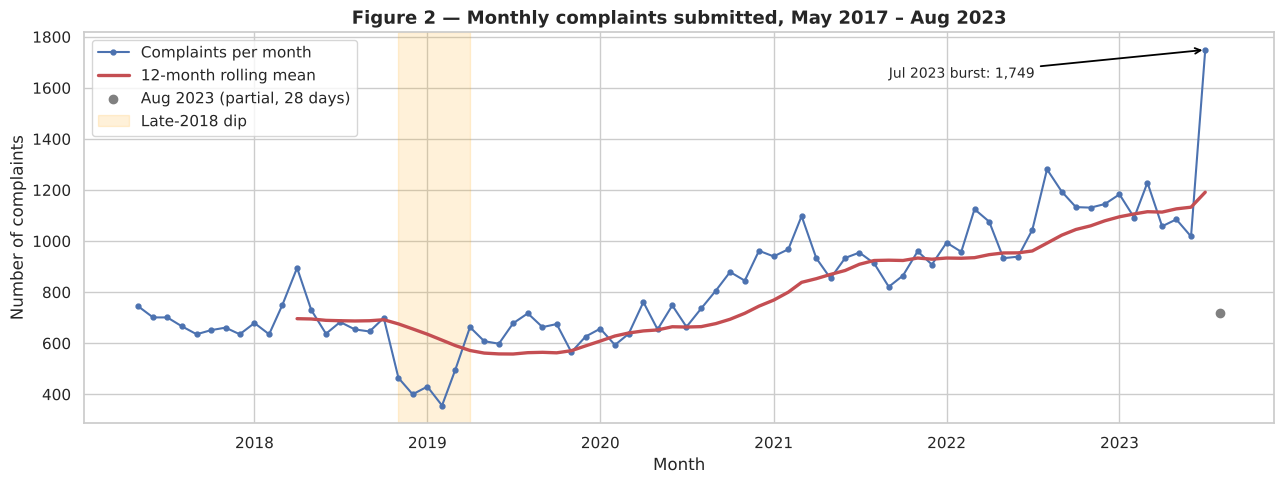

In [13]:
ts = series.copy(); ts.index = ts.index.to_timestamp()
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(ts.index, ts.values, marker="o", ms=3.5, color=PAL[0], label="Complaints per month")
ax.plot(ts.index, ts.rolling(12, min_periods=12).mean(), color=PAL[3], lw=2.4, label="12-month rolling mean")
part = monthly.iloc[-1]; ax.scatter([monthly.index[-1].to_timestamp()], [part.complaints], color="grey", zorder=5, label="Aug 2023 (partial, 28 days)")
ax.axvspan(pd.Timestamp("2018-11-01"), pd.Timestamp("2019-03-31"), color="orange", alpha=0.15, label="Late-2018 dip")
ax.annotate("Jul 2023 burst: 1,749", (pd.Timestamp("2023-07-01"), 1749), xytext=(pd.Timestamp("2021-09-01"), 1640), arrowprops={"arrowstyle": "->", "color": "black", "lw": 1.3}, fontsize=10)
ax.set_title("Figure 2 — Monthly complaints submitted, May 2017 – Aug 2023"); ax.set_xlabel("Month"); ax.set_ylabel("Number of complaints"); ax.legend(loc="upper left")
save_fig("02_monthly_series.png")

,complaints,note,yoy_change_%
year,,,
2017,5394,May-Dec only,NaN
2018,7872,,45.9
2019,7075,,-10.1
2020,8942,,26.4
2021,11149,,24.7
2022,12953,,16.2
2023,9131,Jan-Aug 28 only,-29.5


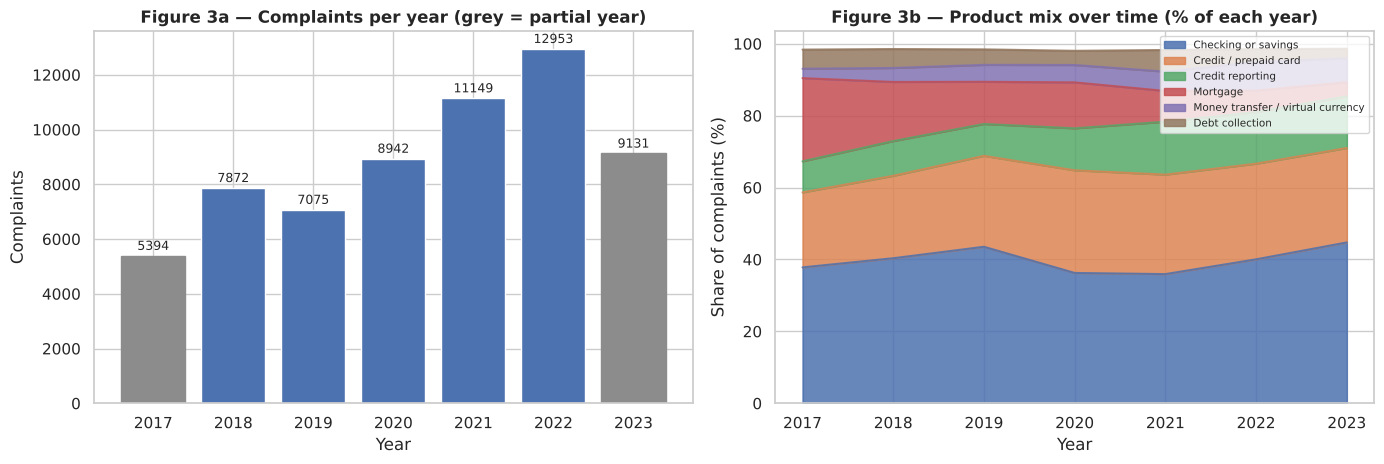

In [14]:
yr = df.groupby("year").size().rename("complaints").to_frame()
yr["note"] = ["May-Dec only", "", "", "", "", "", "Jan-Aug 28 only"]
yr["yoy_change_%"] = (yr.complaints.pct_change() * 100).round(1)
display(yr)
results["by_year"] = df.groupby("year").size().to_dict()
mix = pd.crosstab(df.year, df.product_short, normalize="index") * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
yy = df.groupby("year").size()
bars = ax[0].bar(yy.index.astype(str), yy.values, color=[PAL[0]] * 7)
bars[0].set_color(PAL[7]); bars[-1].set_color(PAL[7]); ax[0].bar_label(bars, padding=2, fontsize=9)
ax[0].set_title("Figure 3a — Complaints per year (grey = partial year)", fontsize=12); ax[0].set_xlabel("Year"); ax[0].set_ylabel("Complaints")
mix[["Checking or savings", "Credit / prepaid card", "Credit reporting", "Mortgage", "Money transfer / virtual currency", "Debt collection"]].plot(kind="area", ax=ax[1], alpha=.85)
ax[1].set_title("Figure 3b — Product mix over time (% of each year)", fontsize=12); ax[1].set_xlabel("Year"); ax[1].set_ylabel("Share of complaints (%)"); ax[1].legend(fontsize=7.5, loc="upper right")
save_fig("03_annual_and_product_mix.png")

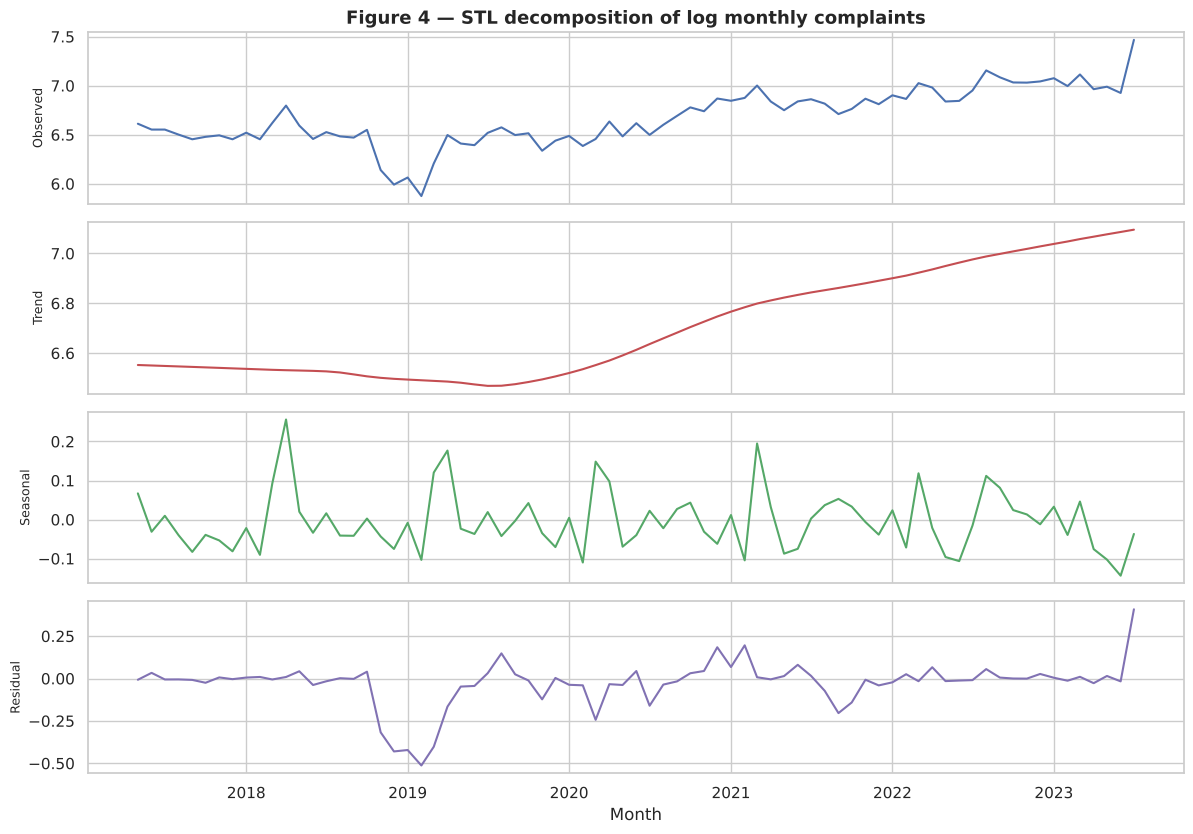

Strength of trend: 0.78 | strength of seasonality: 0.16   (0 = none, 1 = dominant)


In [15]:
stl = STL(np.log(series.astype(float)).values, period=12, robust=True).fit()
comp = pd.DataFrame({"observed": np.log(series.values), "trend": stl.trend, "seasonal": stl.seasonal, "residual": stl.resid}, index=ts.index)
fig, ax = plt.subplots(4, 1, figsize=(12, 8.5), sharex=True)
for a, c, col in zip(ax, comp.columns, [PAL[0], PAL[3], PAL[2], PAL[4]]):
    a.plot(comp.index, comp[c], color=col); a.set_ylabel(c.capitalize(), fontsize=9)
ax[0].set_title("Figure 4 — STL decomposition of log monthly complaints"); ax[-1].set_xlabel("Month")
save_fig("04_stl_decomposition.png")
seas_strength = max(0, 1 - comp.residual.var() / (comp.seasonal + comp.residual).var())
trend_strength = max(0, 1 - comp.residual.var() / (comp.trend + comp.residual).var())
results["seasonal_strength"], results["trend_strength"] = round(float(seas_strength), 2), round(float(trend_strength), 2)
print(f"Strength of trend: {trend_strength:.2f} | strength of seasonality: {seas_strength:.2f}   (0 = none, 1 = dominant)")

**What the history shows.**
* Volume **grew about 2.4 times** between 2018 and 2022 (7,872 to 12,953 complaints; 2017 and 2023 are partial years). The **trend** is the dominant pattern.
* **Seasonality is weak** (strength well below the trend). There is no strong, repeating calendar pattern to exploit, so seasonal methods are not expected to shine.
* Two **structural features** matter for forecasting: a **dip from November 2018 to March 2019** (as low as 356 a month) and a **one-off burst in July 2023** (1,749, about 60% above the previous six months' typical level). Neither follows a calendar pattern. The data do not say why, and this project does not guess.
* Product mix shifts over time: mortgage complaints fall as a share while credit-card and credit-reporting complaints grow.

### 3.3 The July 2023 burst

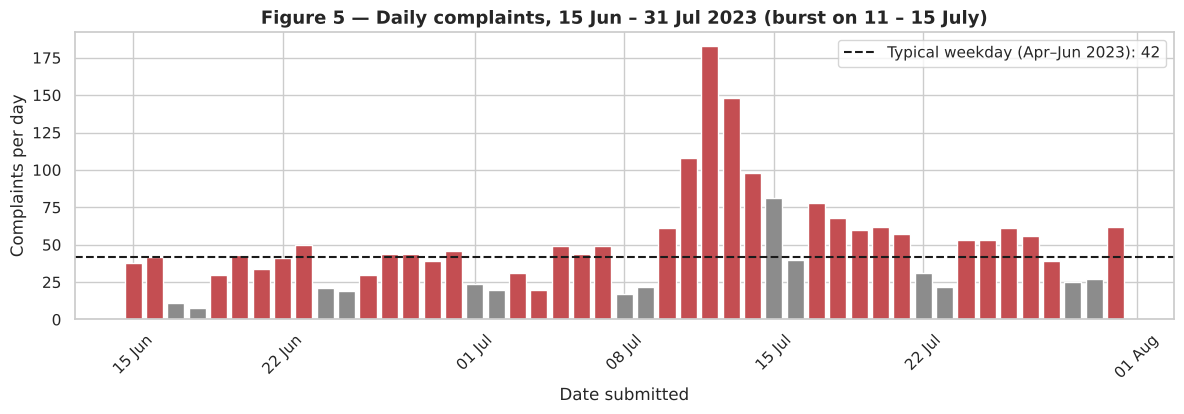

July vs June 2023 by product:
                                    June  July
product_short                                
Checking or savings                 423   883
Credit / prepaid card               281   483
Credit reporting                    168   182
Money transfer / virtual currency    75    77
Mortgage                             33    60

Top issue in July: {'Managing an account': 425, 'Opening an account': 183, 'Problem with a lender or other company charging your account': 110}
Peak day: 2023-07-12 183 complaints


In [16]:
jul = df[(df.date_submitted >= "2023-06-15") & (df.date_submitted <= "2023-07-31")]
daily = jul.groupby("date_submitted").size()
base = df[(df.date_submitted >= "2023-04-01") & (df.date_submitted <= "2023-06-30") & (df.date_submitted.dt.dayofweek < 5)].groupby("date_submitted").size().mean()
fig, ax = plt.subplots(figsize=(12, 4.3))
colors = [PAL[3] if d.dayofweek < 5 else PAL[7] for d in daily.index]
ax.bar(daily.index, daily.values, color=colors)
ax.axhline(base, color="k", ls="--", label=f"Typical weekday (Apr–Jun 2023): {base:.0f}")
ax.set_title("Figure 5 — Daily complaints, 15 Jun – 31 Jul 2023 (burst on 11 – 15 July)"); ax.set_xlabel("Date submitted"); ax.set_ylabel("Complaints per day"); ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); plt.xticks(rotation=45)
save_fig("05_july_2023_burst.png")
j = df[df.year_month == "2023-07"]; jn = df[df.year_month == "2023-06"]
print("July vs June 2023 by product:\n", pd.concat([jn.product_short.value_counts().rename("June"), j.product_short.value_counts().rename("July")], axis=1).head(5).to_string())
print("\nTop issue in July:", j.issue.value_counts().head(3).to_dict())
print("Peak day:", daily.idxmax().date(), int(daily.max()), "complaints")
results["jul23"] = {"total": int((df.year_month == "2023-07").sum()), "peak_day": str(daily.idxmax().date()), "peak": int(daily.max()), "typical_weekday": round(float(base), 1)}

The burst is concentrated on **11 – 15 July 2023** (peak 183 in one day against about 50 on a typical weekday), mostly **checking and savings** complaints about managing and opening accounts, submitted on the web. A burst like this is a one-off event that no model built on past volumes can anticipate. It is kept in the data (it really happened), but Section 6 reports test accuracy **with and without it**.

---
## 4. Defining the forecasting problem
| Item | Definition |
|---|---|
| **Target** | Complaints submitted in a calendar month (count by `Date submitted`) |
| **Forecast horizons** | 1 – 6 months ahead; the operational focus is **1 – 3 months** |
| **Modelling window** | 75 complete months, May 2017 – Jul 2023 (Aug 2023 is partial and excluded) |
| **Calendar effect** | 87% of complaints arrive on weekdays, so months with more weekdays should get slightly more. Models forecast the **complaints per weekday** rate and convert back with the target month's weekday count (Section 6.6 tests whether this adjustment matters). |
| **Metrics** | **MAE** (average miss in complaints), **RMSE** (penalises large misses), **WAPE** = total absolute error ÷ total actual (a % that is stable when volumes change) |

### Features (all computed only from months up to the forecast origin)
Level now (last month's rate), last 3 months, 12-month and 6-month average, recent change, month of year (sine/cosine), and a trend index. There is no information from after the origin in any feature, and hyper-parameters are chosen on validation months only.

### Chronological validation design (rolling origin, expanding window)
| Period | Months forecast | Use |
|---|---|---|
| Training history | May 2017 – Dec 2021 and onwards | Each forecast uses *all* months up to its origin, never later ones |
| **Validation** | Jan 2022 – Dec 2022 (12 months) | Choose settings and the best model |
| **Test** | Jan 2023 – Jul 2023 (7 months) | Touched once, for the final report |

For every target month and every horizon *h*, the model is re-fitted using data up to *h* months before the target. This mimics real use and prevents leakage from future periods.

In [17]:
rate = (series / WD.loc[series.index]).astype(float)           # complaints per weekday
n_wd = lambda p: int(WD.loc[p])
print("Weekday share of complaints:", f"{(df.date_submitted.dt.dayofweek < 5).mean() * 100:.1f}%")
print("Raw correlation of monthly count with weekdays in the month:", round(float(np.corrcoef(series, WD.loc[series.index])[0, 1]), 2), "(weak because the long-term trend dominates)")
VAL = [pd.Period(f"2022-{m:02d}") for m in range(1, 13)]
TEST = [pd.Period(f"2023-{m:02d}") for m in range(1, 8)]
H_MAX = 6
print("Validation targets:", VAL[0], "->", VAL[-1], "| Test targets:", TEST[0], "->", TEST[-1])

Weekday share of complaints: 87.3%
Raw correlation of monthly count with weekdays in the month: 0.05 (weak because the long-term trend dominates)
Validation targets: 2022-01 -> 2022-12 | Test targets: 2023-01 -> 2023-07


## 5. Forecasting methods
| # | Method | Type | Idea |
|---|---|---|---|
| 1 | **Naive** | Baseline | Next month = last month |
| 2 | **Seasonal naive** | Baseline | Same month last year (with weekday adjustment) |
| 3 | **3-month average** | Baseline | Mean of the last 3 months |
| 4 | **6-month median** | Baseline | Median of the last 6 months (ignores a single burst) |
| 5 | **Exponential smoothing (damped trend)** | Statistical | Weighted history with a trend that levels off |
| 6 | **ARIMA** | Statistical | Order chosen by AIC at every origin |
| 7 | **Ridge regression** | Machine learning | Linear model on lag and calendar features |
| 8 | **Gradient boosting** | Machine learning | Shallow trees on the same features |
| 9 | **Ensemble** | Combination | Average of exponential smoothing, ridge and boosting |

The baselines set the bar: a model is only useful if it beats "next month = last month".

In [18]:
def hist_rate(counts, W):
    return counts / W.loc[counts.index]

def f_naive(hist, W, h, tm):      return hist_rate(hist, W).iloc[-1] * W.loc[tm]
def f_snaive(hist, W, h, tm):
    ly = tm - 12
    return (hist_rate(hist, W).get(ly, hist_rate(hist, W).iloc[-1])) * W.loc[tm]
def f_ma3(hist, W, h, tm):        return hist_rate(hist, W).iloc[-3:].mean() * W.loc[tm]
def f_med6(hist, W, h, tm):       return hist_rate(hist, W).iloc[-6:].median() * W.loc[tm]    # robust to a single burst

def f_ets(hist, W, h, tm):
    r = hist_rate(hist, W).values.astype(float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = ExponentialSmoothing(r, trend="add", damped_trend=True, seasonal=None).fit()
    return fit.forecast(h)[-1] * W.loc[tm]

ARIMA_GRID = list(itertools.product([0, 1, 2], [0, 1]))      # (p, q) with d = 1
def arima_best(hist, W):
    r = np.log1p(hist_rate(hist, W).values.astype(float)); best, order = None, None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for p_, q_ in ARIMA_GRID:
            try:
                res = SARIMAX(r, order=(p_, 1, q_)).fit(disp=False)
                if best is None or res.aic < best.aic: best, order = res, (p_, 1, q_)
            except Exception:
                continue
    return best, order

def f_arima(hist, W, h, tm):
    best, _ = arima_best(hist, W)
    return np.expm1(best.forecast(h)[-1]) * W.loc[tm]

def ml_features(r, t, tm, h, base_idx):
    # r: log1p rate array (history only); t: index of the forecast origin inside r
    return [r[t], r[t - 1], r[t - 2], r[t - 11:t + 1].mean(), r[t - 5:t + 1].mean(), r[t] - r[t - 1],
            np.sin(2 * np.pi * tm.month / 12), np.cos(2 * np.pi * tm.month / 12), base_idx + t + h]

def make_ml(kind, alpha=3.0, depth=2, n_est=150):
    def f(hist, W, h, tm):
        r = np.log1p(hist_rate(hist, W).values.astype(float)); n = len(r); idx = hist.index
        X, y = [], []
        for t in range(12, n - h):
            X.append(ml_features(r, t, idx[t + h], h, 0)); y.append(r[t + h])
        X, y = np.array(X), np.array(y); xr = np.array([ml_features(r, n - 1, tm, h, 0)])
        if kind == "ridge":
            mu, sd = X.mean(0), X.std(0) + 1e-9
            pred = Ridge(alpha=alpha).fit((X - mu) / sd, y).predict((xr - mu) / sd)[0]
        else:
            pred = GradientBoostingRegressor(n_estimators=n_est, max_depth=depth, learning_rate=0.05, subsample=0.8,
                                             random_state=SEED).fit(X, y).predict(xr)[0]
        return float(np.expm1(pred) * W.loc[tm])
    return f

def backtest(models, counts, W, targets, horizons=range(1, H_MAX + 1), min_hist=24):
    rows = []
    for tm in targets:
        for h in horizons:
            hist = counts[counts.index <= tm - h]
            if len(hist) < min_hist: continue
            for name, fn in models.items():
                rows.append({"target": tm, "horizon": h, "model": name, "actual": float(counts[tm]), "forecast": float(fn(hist, W, h, tm))})
    return pd.DataFrame(rows)

def metrics(bt):
    g = bt.assign(err=bt.forecast - bt.actual)
    out = g.groupby(["model", "horizon"]).apply(lambda x: pd.Series({
        "MAE": x.err.abs().mean(), "RMSE": np.sqrt((x.err ** 2).mean()),
        "WAPE": x.err.abs().sum() / x.actual.sum(), "bias": x.err.mean(), "n": len(x)})).reset_index()
    return out
print("Methods defined.")

Methods defined.


### 5.1 Tuning on the validation months only
The two machine-learning models have settings (Ridge penalty; boosting depth). They are chosen by validation accuracy at horizons 1 – 3. **The test months are not used for tuning.**

In [19]:
tune_rows = []
for a in [0.1, 1, 3, 10, 30, 100]:
    bt = backtest({"m": make_ml("ridge", alpha=a)}, series, WD, VAL, horizons=[1, 2, 3])
    tune_rows.append({"model": "Ridge", "setting": f"alpha={a}", "val_WAPE_h1-3": metrics(bt).WAPE.mean()})
for dp, ne in [(1, 100), (2, 150), (3, 150)]:
    bt = backtest({"m": make_ml("gbm", depth=dp, n_est=ne)}, series, WD, VAL, horizons=[1, 2, 3])
    tune_rows.append({"model": "Gradient boosting", "setting": f"depth={dp}, trees={ne}", "val_WAPE_h1-3": metrics(bt).WAPE.mean()})
tune = pd.DataFrame(tune_rows); tune["val_WAPE_h1-3"] = tune["val_WAPE_h1-3"].round(4)
best_ridge = tune[tune.model == "Ridge"].sort_values("val_WAPE_h1-3").iloc[0].setting
best_gbm = tune[tune.model == "Gradient boosting"].sort_values("val_WAPE_h1-3").iloc[0].setting
results["tuning"] = tune.to_dict("records"); results["best_ridge"], results["best_gbm"] = best_ridge, best_gbm
print("Chosen on validation:", best_ridge, "|", best_gbm)
tune

Chosen on validation: alpha=0.1 | depth=2, trees=150


,model,setting,val_WAPE_h1-3
0,Ridge,alpha=0.1,0.0760
1,Ridge,alpha=1,0.0768
2,Ridge,alpha=3,0.0777
3,Ridge,alpha=10,0.0823
4,Ridge,alpha=30,0.0982
5,Ridge,alpha=100,0.1380
6,Gradient boosting,"depth=1, trees=100",0.1104
7,Gradient boosting,"depth=2, trees=150",0.0973
8,Gradient boosting,"depth=3, trees=150",0.1003


In [20]:
RIDGE_ALPHA = float(best_ridge.split("=")[1])
g_depth, g_trees = [int(x.split("=")[1]) for x in best_gbm.split(", ")]
_ridge, _gbm = make_ml("ridge", alpha=RIDGE_ALPHA), make_ml("gbm", depth=g_depth, n_est=g_trees)
def f_ens(hist, W, h, tm):
    return float(np.mean([f_ets(hist, W, h, tm), _ridge(hist, W, h, tm), _gbm(hist, W, h, tm)]))
MODELS = {"Naive": f_naive, "Seasonal naive": f_snaive, "3-month average": f_ma3, "6-month median": f_med6,
          "Exp. smoothing (damped)": f_ets, "ARIMA": f_arima,
          "Ridge regression": _ridge, "Gradient boosting": _gbm, "Ensemble (ETS+Ridge+GBM)": f_ens}
BASELINES = ["Naive", "Seasonal naive", "3-month average", "6-month median"]

bt_val = backtest(MODELS, series, WD, VAL)
bt_test = backtest(MODELS, series, WD, TEST)
m_val, m_test = metrics(bt_val), metrics(bt_test)
print("Backtest forecasts:", len(bt_val), "validation +", len(bt_test), "test")

Backtest forecasts: 648 validation + 378 test


## 6. Results
### 6.1 Validation (2022): which method is best?

In [21]:
def tbl(m, horizons=(1, 2, 3)):
    t = m[m.horizon.isin(horizons)].groupby("model")[["MAE", "RMSE", "WAPE"]].mean().round(3)
    t["WAPE"] = (t["WAPE"] * 100).round(1)
    return t.rename(columns={"WAPE": "WAPE_%"})

val_tbl = tbl(m_val).sort_values("WAPE_%")
print("Validation, average over horizons 1-3 months:")
display(val_tbl)
best_model = val_tbl.drop(index=BASELINES).index[0]
best_baseline = val_tbl.loc[BASELINES].index[0]
results["val_table"] = val_tbl.reset_index().to_dict("records"); results["best_model"], results["best_baseline"] = best_model, best_baseline
print(f"Selected on validation: {best_model}   (best baseline: {best_baseline})")

Validation, average over horizons 1-3 months:


,MAE,RMSE,WAPE_%
model,,,
Ridge regression,82.046,111.595,7.6
Ensemble (ETS+Ridge+GBM),90.677,109.627,8.4
6-month median,102.480,117.480,9.5
Gradient boosting,105.075,133.836,9.7
Naive,106.010,129.986,9.8
ARIMA,106.010,129.986,9.8
Exp. smoothing (damped),106.514,125.880,9.9
3-month average,114.478,129.437,10.6
Seasonal naive,155.594,200.080,14.4


Selected on validation: Ridge regression   (best baseline: Naive)


### 6.2 Test (Jan – Jul 2023): the honest result
The selected model was fixed on validation. Test numbers are reported with and without **July 2023**, the one-off burst that no model could anticipate.

In [22]:
test_all = tbl(m_test).sort_values("WAPE_%")
bt_test_ex = bt_test[bt_test.target != pd.Period("2023-07")]
test_ex = tbl(metrics(bt_test_ex)).sort_values("WAPE_%")
print("TEST, all 7 months (includes the July 2023 burst), average over horizons 1-3:"); display(test_all)
print("TEST excluding July 2023, average over horizons 1-3:"); display(test_ex)
results["test_table_all"] = test_all.reset_index().to_dict("records"); results["test_table_ex"] = test_ex.reset_index().to_dict("records")

TEST, all 7 months (includes the July 2023 burst), average over horizons 1-3:


,MAE,RMSE,WAPE_%
model,,,
Gradient boosting,141.442,270.013,11.8
6-month median,145.373,252.915,12.1
3-month average,151.057,267.679,12.6
Ensemble (ETS+Ridge+GBM),156.860,266.381,13.0
ARIMA,157.024,285.109,13.1
Exp. smoothing (damped),157.896,280.356,13.1
Naive,157.024,285.109,13.1
Ridge regression,175.124,259.681,14.6
Seasonal naive,186.642,284.159,15.5


TEST excluding July 2023, average over horizons 1-3:


,MAE,RMSE,WAPE_%
model,,,
Gradient boosting,48.577,60.144,4.4
ARIMA,62.432,82.530,5.6
Naive,62.432,82.530,5.6
3-month average,63.930,88.297,5.8
6-month median,64.187,89.102,5.8
Exp. smoothing (damped),66.439,88.795,6.0
Ensemble (ETS+Ridge+GBM),72.925,96.932,6.6
Seasonal naive,100.249,106.613,9.0
Ridge regression,108.289,144.974,9.7


In [23]:
orders = []
for tm in VAL + TEST:
    _, o_ = arima_best(series[series.index <= tm - 1], WD); orders.append(o_)
arima_orders = pd.Series(orders).astype(str).value_counts().rename("origins").to_frame()
print("ARIMA order chosen by AIC at each 1-month-ahead origin (validation + test):"); display(arima_orders)
results["arima_orders"] = arima_orders.origins.to_dict()

ARIMA order chosen by AIC at each 1-month-ahead origin (validation + test):


,origins
"(0, 1, 0)",19


In [24]:
allbt = pd.concat([bt_val, bt_test]); allbt = allbt[allbt.horizon.isin([1, 2, 3])].copy()
allbt["window"] = np.select([allbt.target <= pd.Period("2022-06"), allbt.target <= pd.Period("2022-12")], ["2022 Jan–Jun", "2022 Jul–Dec"], "2023 Jan–Jul")
stab = allbt.assign(ae=(allbt.forecast - allbt.actual).abs()).groupby(["model", "window"]).apply(lambda x: x.ae.sum() / x.actual.sum() * 100).unstack().round(1)
stab = stab.loc[["Naive", "6-month median", "Ridge regression", "Gradient boosting", "Ensemble (ETS+Ridge+GBM)"]]
results["stability"] = stab.reset_index().to_dict("records")
print("WAPE (%) by 6-month window, horizons 1-3: does the ranking hold from one window to the next?")
stab

WAPE (%) by 6-month window, horizons 1-3: does the ranking hold from one window to the next?


window,2022 Jan–Jun,2022 Jul–Dec,2023 Jan–Jul
model,,,
Naive,10.5,9.2,13.1
6-month median,12.3,7.1,12.1
Ridge regression,10.6,5.0,14.6
Gradient boosting,7.3,11.8,11.8
Ensemble (ETS+Ridge+GBM),9.4,7.5,13.0


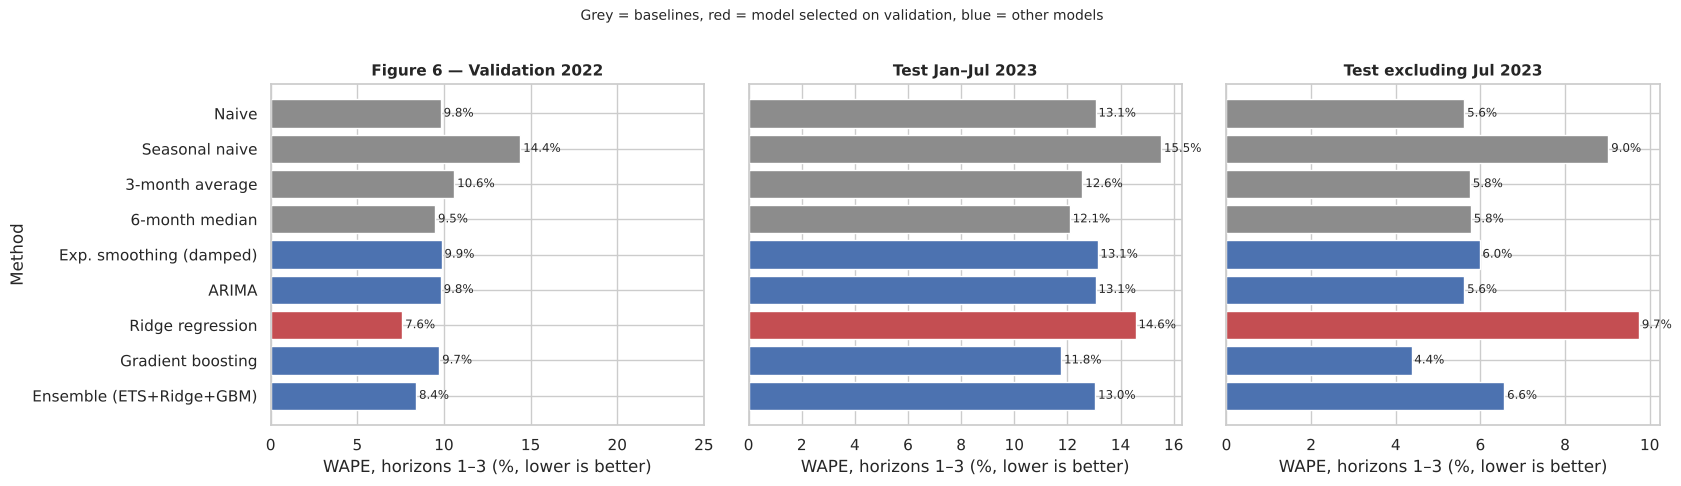

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
order = list(MODELS)
for a, (lab, m_) in zip(ax, [("Validation 2022", m_val), ("Test Jan–Jul 2023", m_test), ("Test excluding Jul 2023", metrics(bt_test_ex))]):
    t = m_[m_.horizon.isin([1, 2, 3])].groupby("model").WAPE.mean().reindex(order) * 100
    cols = [PAL[7] if n in BASELINES else (PAL[3] if n == best_model else PAL[0]) for n in order]
    bars = a.barh(order[::-1], t.values[::-1], color=cols[::-1]); a.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=8.5)
    a.set_title(f"Figure 6 — {lab}" if lab.startswith("Val") else lab, fontsize=11); a.set_xlabel("WAPE, horizons 1–3 (%, lower is better)")
ax[0].set_ylabel("Method"); ax[0].set_xlim(0, max(25, ax[0].get_xlim()[1]))
fig.suptitle("Grey = baselines, red = model selected on validation, blue = other models", fontsize=10, y=1.01)
save_fig("06_model_comparison.png")

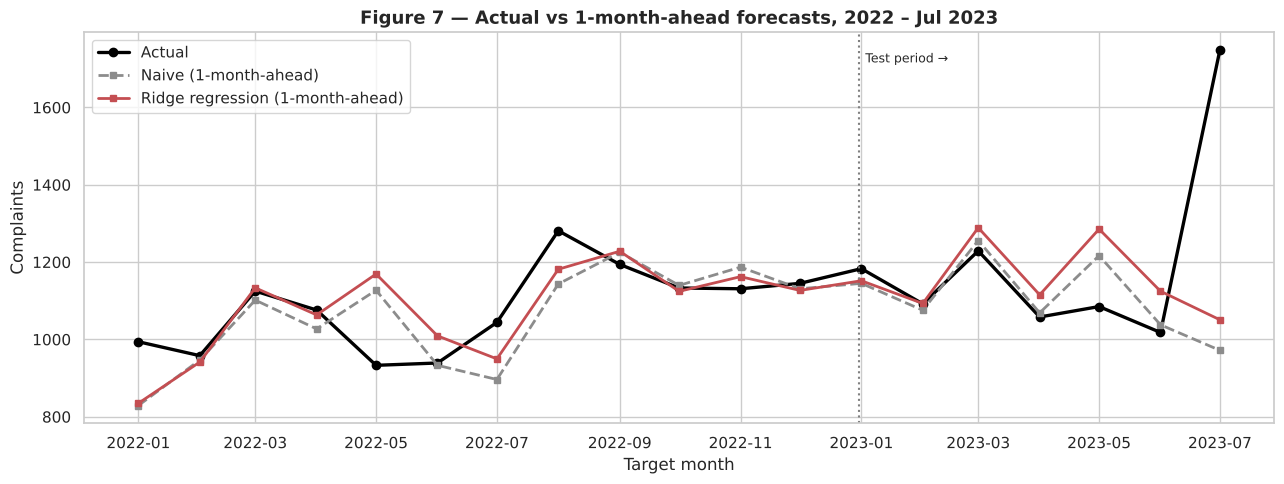

In [26]:
sel = bt_val.pipe(lambda d: d[d.model.isin(["Naive", best_model, "Seasonal naive"]) & (d.horizon == 1)])
sel = pd.concat([sel, bt_test[bt_test.model.isin(["Naive", best_model, "Seasonal naive"]) & (bt_test.horizon == 1)]])
fig, ax = plt.subplots(figsize=(13, 5))
act = pd.concat([series[VAL], series[TEST]]); act.index = act.index.to_timestamp()
ax.plot(act.index, act.values, color="black", lw=2.4, marker="o", label="Actual")
for name, col, ls in [("Naive", PAL[7], "--"), (best_model, PAL[3], "-")]:
    s_ = sel[sel.model == name].set_index("target").forecast; s_.index = s_.index.to_timestamp()
    ax.plot(s_.index, s_.values, color=col, ls=ls, marker="s", ms=4, lw=2, label=f"{name} (1-month-ahead)")
ax.axvline(pd.Timestamp("2022-12-31"), color="grey", ls=":"); ax.text(pd.Timestamp("2023-01-03"), ax.get_ylim()[1] * 0.97, "Test period →", fontsize=9, va="top")
ax.set_title("Figure 7 — Actual vs 1-month-ahead forecasts, 2022 – Jul 2023"); ax.set_xlabel("Target month"); ax.set_ylabel("Complaints"); ax.legend(loc="upper left")
save_fig("07_actual_vs_forecast.png")

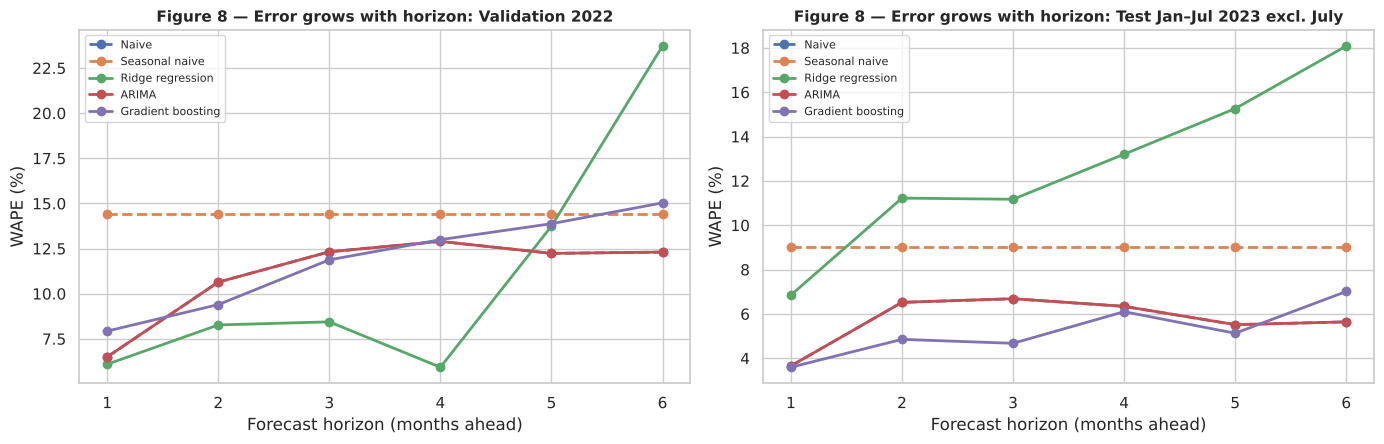

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for a, (lab, m_) in zip(ax, [("Validation 2022", m_val), ("Test Jan–Jul 2023 excl. July", metrics(bt_test_ex))]):
    for name in ["Naive", "Seasonal naive", best_model, "ARIMA", "Gradient boosting"]:
        t = m_[m_.model == name].set_index("horizon").WAPE * 100
        a.plot(t.index, t.values, marker="o", label=name, lw=2, ls="--" if name in BASELINES else "-")
    a.set_title(f"Figure 8 — Error grows with horizon: {lab}", fontsize=11); a.set_xlabel("Forecast horizon (months ahead)"); a.set_ylabel("WAPE (%)"); a.legend(fontsize=8)
save_fig("08_error_by_horizon.png")

**Reading the comparison**
* **Validation (2022):** Ridge regression is best (WAPE 7.6%), then the ensemble (8.4%); the best simple baseline, *Naive*, scores 9.8%. Seasonal naive is clearly worst (14.4%), consistent with the weak seasonality found in Section 3.
* **Test (Jan – Jul 2023):** the picture changes. Gradient boosting is best (11.8%; 4.4% without July), the Naive baseline scores 13.1% (5.6%), and **Ridge, the validation winner, falls to 14.6% (9.7% without July), worse than naive.** The method that looked best on validation did not hold up.
* **ARIMA is the same as Naive.** The AIC search chose a plain random walk, ARIMA(0,1,0), at all 19 origins. That is evidence that month-to-month volume behaves like a random walk with level shifts, which is why "next month = last month" is so hard to beat.
* **Rankings are unstable across windows** (stability table): Ridge scores 5.0% in the second half of 2022 but 14.6% in 2023; gradient boosting shows the reverse pattern. With 75 months, the differences between methods are mostly noise.
* **Error grows with the horizon** (Figure 8). Ridge in particular is erratic beyond 3 months (23.7% at 6 months in validation), so only horizons of 1 – 3 months are used for planning.
* **In plain terms:** a typical 1 – 3 month forecast misses by roughly 8 – 13% of monthly volume (about 80 – 160 complaints), and the best model improves on "repeat last month" by at most about 2 percentage points.

### 6.3 Error analysis
Where does the selected model go wrong, and is it systematically biased?

Ridge regression, 1-month-ahead: mean error (bias) = -17.5 complaints | MAE = 102.3 | median abs % error = 4.9%


,target,actual,forecast,error,abs_pct_err
330,2023-07,1749.0,1050.7,-698.3,39.9
222,2022-05,933.0,1169.2,236.2,25.3
222,2023-05,1085.0,1285.4,200.4,18.5
6,2022-01,994.0,834.8,-159.2,16.0
276,2023-06,1018.0,1124.7,106.7,10.5
330,2022-07,1044.0,949.6,-94.4,9.0


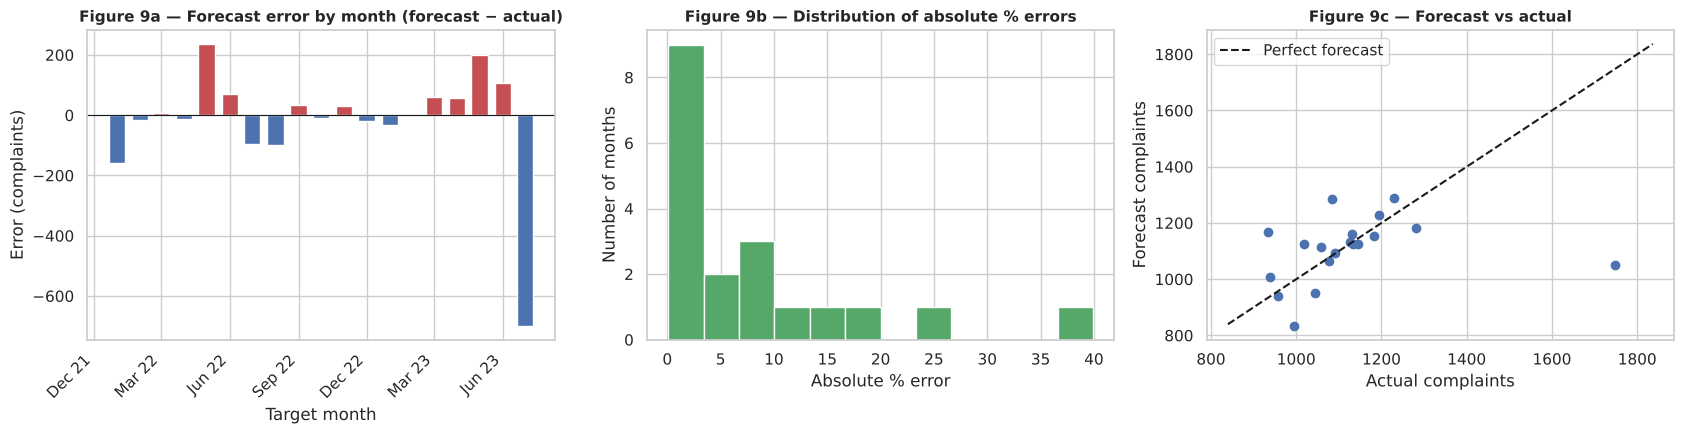

In [28]:
e = pd.concat([bt_val.assign(period="validation"), bt_test.assign(period="test")])
e = e[(e.model == best_model) & (e.horizon == 1)].copy()
e["error"] = e.forecast - e.actual; e["abs_pct_err"] = (e.error.abs() / e.actual * 100)
e["target_ts"] = e.target.dt.to_timestamp()
print(f"{best_model}, 1-month-ahead: mean error (bias) = {e.error.mean():+.1f} complaints | MAE = {e.error.abs().mean():.1f} | median abs % error = {e.abs_pct_err.median():.1f}%")
display(e.sort_values("abs_pct_err", ascending=False).head(6)[["target", "actual", "forecast", "error", "abs_pct_err"]].round(1))
results["worst_months"] = e.sort_values("abs_pct_err", ascending=False).head(4).assign(target=lambda d: d.target.astype(str))[["target", "actual", "forecast", "abs_pct_err"]].round(1).to_dict("records")
results["bias_h1"] = round(float(e.error.mean()), 1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
colors = [PAL[3] if v > 0 else PAL[0] for v in e.error]
ax[0].bar(e.target_ts, e.error, width=22, color=colors); ax[0].axhline(0, color="k", lw=.8)
ax[0].set_title("Figure 9a — Forecast error by month (forecast − actual)", fontsize=11); ax[0].set_xlabel("Target month"); ax[0].set_ylabel("Error (complaints)")
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); ax[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3)); plt.setp(ax[0].get_xticklabels(), rotation=45, ha="right")
ax[1].hist(e.abs_pct_err, bins=12, color=PAL[2]); ax[1].set_title("Figure 9b — Distribution of absolute % errors", fontsize=11)
ax[1].set_xlabel("Absolute % error"); ax[1].set_ylabel("Number of months")
ax[2].scatter(e.actual, e.forecast, color=PAL[0]); lim = [e.actual.min() * .9, e.actual.max() * 1.05]
ax[2].plot(lim, lim, color="k", ls="--", label="Perfect forecast"); ax[2].set_title("Figure 9c — Forecast vs actual", fontsize=11)
ax[2].set_xlabel("Actual complaints"); ax[2].set_ylabel("Forecast complaints"); ax[2].legend()
save_fig("09_error_analysis.png")

In [29]:
resid = (e.set_index("target").actual - e.set_index("target").forecast)
lag1 = float(resid.autocorr(1))
print(f"Lag-1 autocorrelation of forecast errors: {lag1:.2f}  (near 0 = no obvious pattern left unused)")
print("Share of months where forecast was too high:", f"{(e.error > 0).mean() * 100:.0f}%")
results["err_autocorr"] = round(lag1, 2)

Lag-1 autocorrelation of forecast errors: -0.06  (near 0 = no obvious pattern left unused)
Share of months where forecast was too high: 53%


**What the errors show.**
* The **largest misses are turning points**: the July 2023 burst (actual 1,749 vs forecast 1,051, 40% too low), May 2022 (forecast 25% too high after a spike in March/April) and May 2023 (18% too high). Forecasts that lean on last month's level overshoot when volume falls back and undershoot when it jumps.
* The **average error is −17.5 complaints** (forecasts slightly low), almost entirely due to July 2023.
* Errors have almost no **autocorrelation** (−0.06): the model is not leaving an obvious pattern unused. The remaining error is mostly genuine unpredictability, not a fixable modelling flaw.

### 6.4 Partial-month check: August 2023
August 2023 was never used for training or evaluation. It is a free out-of-sample check, **scaled to the 20 weekdays actually covered**.

In [30]:
aug = pd.Period("2023-08"); W_aug = WD.copy()
chk_models = list(dict.fromkeys([best_model, "Naive", "6-month median", "Gradient boosting"]))
covered = weekdays_in_month(aug, last_day); full = weekdays_in_month(aug)
actual_part = int(monthly.loc[aug, "complaints"])
chk = pd.DataFrame({"forecast_full_month": [MODELS[k](series, WD, 1, aug) for k in chk_models]}, index=chk_models)
chk["scaled_to_covered_weekdays"] = chk.forecast_full_month * covered / full
chk["actual_(28_days)"] = actual_part
chk["error_%"] = ((chk.scaled_to_covered_weekdays - actual_part) / actual_part * 100).round(1)
results["aug_check"] = chk.round(1).reset_index().rename(columns={"index": "model"}).to_dict("records")
chk.round(1)

,forecast_full_month,scaled_to_covered_weekdays,actual_(28_days),error_%
Ridge regression,1843.1,1602.7,717,123.5
Naive,1915.6,1665.7,717,132.3
6-month median,1222.8,1063.3,717,48.3
Gradient boosting,1916.9,1666.9,717,132.5


**What this shows.** After the July burst, August came back down (about 36 complaints per weekday, against 46 in June and 83 in July). Every method that leans on last month's level (Ridge, Naive, Gradient boosting) **forecast more than double the actual volume (+123% to +133%)**. The 6-month median, which ignores a single burst, is much closer (+48%) though still high. The practical lesson is that a one-off burst must not be carried forward blindly: it needs flagging and a human decision about whether it is a new level or a one-off.

### 6.5 Statistical significance of the improvement
With so few test months, a model that looks better may not be reliably better. A simple paired check of the absolute errors against the Naive baseline (all months and horizons 1 – 3, validation + test):

In [31]:
from scipy import stats
allbt = pd.concat([bt_val, bt_test]); allbt = allbt[allbt.horizon.isin([1, 2, 3])]
pivot = allbt.assign(ae=(allbt.forecast - allbt.actual).abs()).pivot_table(index=["target", "horizon"], columns="model", values="ae")
rows = []
for name in MODELS:
    if name == "Naive": continue
    d_ = pivot["Naive"] - pivot[name]
    w = stats.wilcoxon(d_) if (d_ != 0).any() else None
    rows.append({"model": name, "mean_abs_error_saved_vs_naive": round(d_.mean(), 1), "months_better_%": round((d_ > 0).mean() * 100, 0), "wilcoxon_p": round(w.pvalue, 3) if w else np.nan})
sig = pd.DataFrame(rows).sort_values("mean_abs_error_saved_vs_naive", ascending=False); results["significance"] = sig.to_dict("records")
sig

,model,mean_abs_error_saved_vs_naive,months_better_%,wilcoxon_p
7,Ensemble (ETS+Ridge+GBM),9.7,56.0,0.147
5,Ridge regression,8.5,56.0,0.522
2,6-month median,6.5,56.0,0.369
6,Gradient boosting,6.3,60.0,0.268
4,ARIMA,0.0,37.0,0.733
3,Exp. smoothing (damped),-0.6,40.0,0.528
1,3-month average,-3.2,51.0,0.908
0,Seasonal naive,-42.2,42.0,0.022


**No method is reliably better than Naive.** The average absolute-error saving over Naive is small (up to about 10 complaints a month for the ensemble) and no p-value is below 0.14. The only significant difference is that **seasonal naive is worse** (p = 0.02). These p-values are optimistic because forecasts for neighbouring months and horizons are correlated, so even this evidence of "no reliable gain" is generous to the models. The honest conclusion is that, on this data, the extra machinery cannot yet be shown to beat a simple baseline.

### 6.6 Sensitivity: does dropping May 2017 or the burst change the picture?

In [32]:
def quick(series_, targets, models=("Naive", best_model), horizons=(1, 2, 3)):
    bt = backtest({k: MODELS[k] for k in models}, series_, WD, targets, horizons=horizons)
    return metrics(bt).groupby("model").WAPE.mean().mul(100).round(1)
sens = pd.DataFrame({
    "Base case": quick(series, VAL + TEST),
    "Without May 2017": quick(series.iloc[1:], VAL + TEST),
    "Without Jul 2023 target": quick(series, VAL + TEST[:-1]),
})
results["sensitivity"] = sens.reset_index().to_dict("records")
raw_naive = metrics(backtest({"Naive (raw count)": lambda hist, W, h, tm: float(hist.iloc[-1])}, series, WD, VAL + TEST, horizons=(1, 2, 3))).WAPE.mean() * 100
results["naive_raw_wape"] = round(float(raw_naive), 1)
print(f"Naive WITHOUT the weekday adjustment (base case window): WAPE {raw_naive:.1f}%  vs  {sens.loc['Naive', 'Base case']}% with it")
sens

Naive WITHOUT the weekday adjustment (base case window): WAPE 11.8%  vs  11.1% with it


,Base case,Without May 2017,Without Jul 2023 target
model,,,
Naive,11.1,11.1,8.4
Ridge regression,10.3,10.0,8.3


* **May 2017** makes no difference (Naive 11.1% either way; Ridge 10.3% vs 10.0%), so keeping the first month is safe.
* **The July 2023 burst** is the main driver of the headline error: excluding it as a target lowers WAPE from about 11% to about 8% and shrinks Ridge's apparent edge over Naive from 0.8 to 0.1 points. The model's advantage in the full test comes from how it handled one unusual month, not from consistent skill.
* **The weekday adjustment** is a low-risk calendar correction: using raw counts instead gives a Naive WAPE of 11.8%, against 11.1% with the adjustment.

---
## 7. Product-level forecasts
Where there are enough records, the same process is applied to individual products (1-month-ahead, same validation and test months). Products with fewer than about 30 complaints a month are too sparse to forecast. A month without any complaint for a product is a **genuine zero** (every month is covered overall), so the product-by-month table is filled with zeros.

In [33]:
pm = pd.crosstab(df.year_month, df.product_short).reindex(full_index, fill_value=0)       # genuine zeros, not missing
pm = pm.loc[series.index]
avg = pm.mean().sort_values(ascending=False)
print("Average complaints per month by product (modelling window):"); display(avg.round(1).to_frame("avg_per_month"))
print("Zero-complaint months per product:", (pm == 0).sum()[(pm == 0).sum() > 0].to_dict())
eligible = avg[avg >= 30].index.tolist()
results["eligible_products"] = eligible

Average complaints per month by product (modelling window):


,avg_per_month
product_short,
Checking or savings,326.8
Credit / prepaid card,213.3
Credit reporting,101.2
Mortgage,87.5
Money transfer / virtual currency,45.6
Debt collection,36.1
Vehicle loan or lease,8.3
Payday / title / personal loan,4.4
Student loan,0.5


Zero-complaint months per product: {'Payday / title / personal loan': 3, 'Student loan': 46}


In [34]:
prod_models = {k: MODELS[k] for k in ["Naive", "Seasonal naive", "Exp. smoothing (damped)", "Ridge regression", "Gradient boosting"]}
prod_rows = []
for p_ in eligible:
    bt = backtest(prod_models, pm[p_], WD, VAL + TEST, horizons=[1])
    mm = metrics(bt)
    for _, r_ in mm.iterrows():
        prod_rows.append({"product": p_, "model": r_.model, "MAE": r_.MAE, "WAPE_%": r_.WAPE * 100})
pr = pd.DataFrame(prod_rows)
wide = pr.pivot(index="product", columns="model", values="WAPE_%").round(1)
wide["best_model"] = wide.idxmin(axis=1); wide["avg_per_month"] = avg[wide.index].round(0)
results["product_wape"] = wide.reset_index().to_dict("records")
wide

model,Exp. smoothing (damped),Gradient boosting,Naive,Ridge regression,Seasonal naive,best_model,avg_per_month
product,,,,,,,
Checking or savings,13.3,13.9,13.2,14.1,25.0,Naive,327.0
Credit / prepaid card,11.3,11.5,12.2,12.0,16.2,Exp. smoothing (damped),213.0
Credit reporting,10.4,12.6,10.3,11.7,21.3,Naive,101.0
Debt collection,20.0,22.8,20.4,21.9,46.5,Exp. smoothing (damped),36.0
Money transfer / virtual currency,12.8,13.3,10.3,19.3,38.5,Naive,46.0
Mortgage,21.1,22.3,21.9,23.8,34.9,Exp. smoothing (damped),88.0


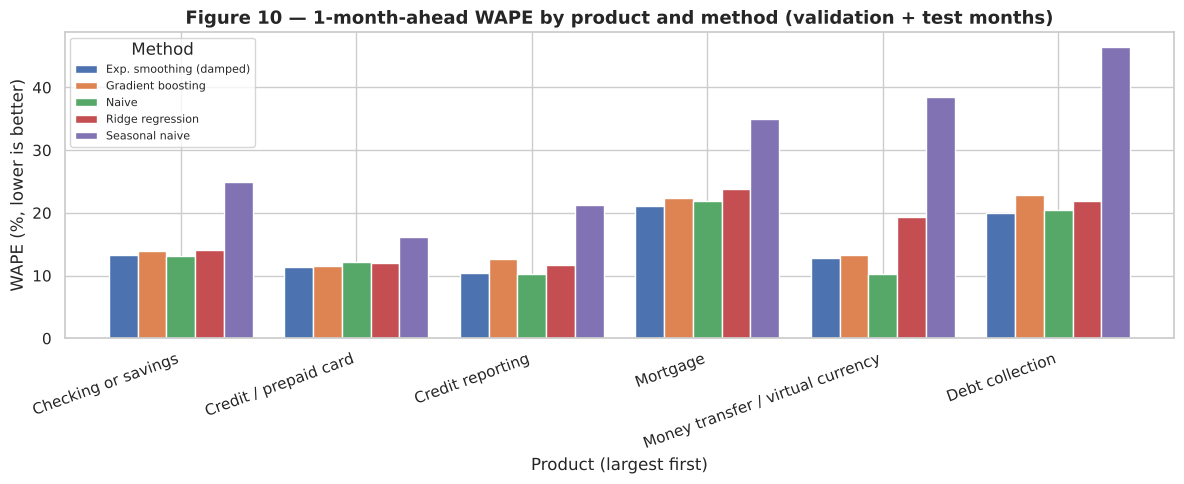

In [35]:
fig, ax = plt.subplots(figsize=(12, 5))
w2 = wide.drop(columns=["best_model", "avg_per_month"]).loc[avg[eligible].index]
w2.plot(kind="bar", ax=ax, width=0.82)
ax.set_title("Figure 10 — 1-month-ahead WAPE by product and method (validation + test months)")
ax.set_xlabel("Product (largest first)"); ax.set_ylabel("WAPE (%, lower is better)"); ax.legend(title="Method", fontsize=8)
plt.xticks(rotation=20, ha="right")
save_fig("10_product_level_wape.png")

**Findings.** Six products have at least 30 complaints a month. Their 1-month-ahead WAPE ranges from about 10% (credit reporting, money transfer) to 20 – 22% (debt collection, mortgage). For **every product the winner is Naive or exponential smoothing; the machine-learning models do not help.** The smaller products have the highest relative error because small counts are noisy by nature (a product averaging 36 a month has a built-in random variation of about 17%), and mortgage complaints are also trending down. Student loans (46 zero-complaint months, about 0.5 a month) and the other low-volume products are too sparse to forecast; their zero months are genuine zeros, not gaps.

---
## 8. Forecasting the future
The selected model is re-fitted on **all** complete months (May 2017 – Jul 2023) and used to forecast the next three months, the horizon range that was validated. A second line shows a **robust-level scenario** that treats the July burst as a one-off. **Uncertainty ranges** come from the model's own backtest errors at each horizon (the 10th and 90th percentile of actual ÷ forecast), so they reflect how wrong the model has really been. They are based on only about 19 backtest months per horizon, so treat them as rough.

In [36]:
bt_all = pd.concat([bt_val, bt_test])
bt_best = bt_all[bt_all.model == best_model].copy()
bt_best["ratio"] = bt_best.actual / bt_best.forecast
q = bt_best.groupby("horizon").ratio.quantile([0.1, 0.5, 0.9]).unstack()
fut_rows = []
W_ext = pd.Series({p: weekdays_in_month(p) for p in pd.period_range("2017-05", "2024-03", freq="M")})
for h in range(1, 4):
    tm = pd.Period("2023-07") + h
    fc = MODELS[best_model](series, W_ext, h, tm)
    fut_rows.append({"month": str(tm), "horizon": h, "forecast": fc, "low_80": fc * q.loc[h, 0.1], "high_80": fc * q.loc[h, 0.9],
                     "robust_level_scenario": MODELS["6-month median"](series, W_ext, h, tm), "weekdays": int(W_ext[tm])})
future = pd.DataFrame(fut_rows).round(0)
future.loc[future.month == "2023-08", "note"] = "Full-month equivalent (actual data cover 28 days only)"
results["future"] = future.fillna("").to_dict("records")
future

,month,horizon,forecast,low_80,high_80,robust_level_scenario,weekdays,note
0,2023-08,1,1843.0,1646.0,2060.0,1223.0,23,Full-month equivalent (actual data cover 28 days only)
1,2023-09,2,1493.0,1198.0,1717.0,1117.0,21,NaN
2,2023-10,3,1478.0,1178.0,1595.0,1170.0,22,NaN


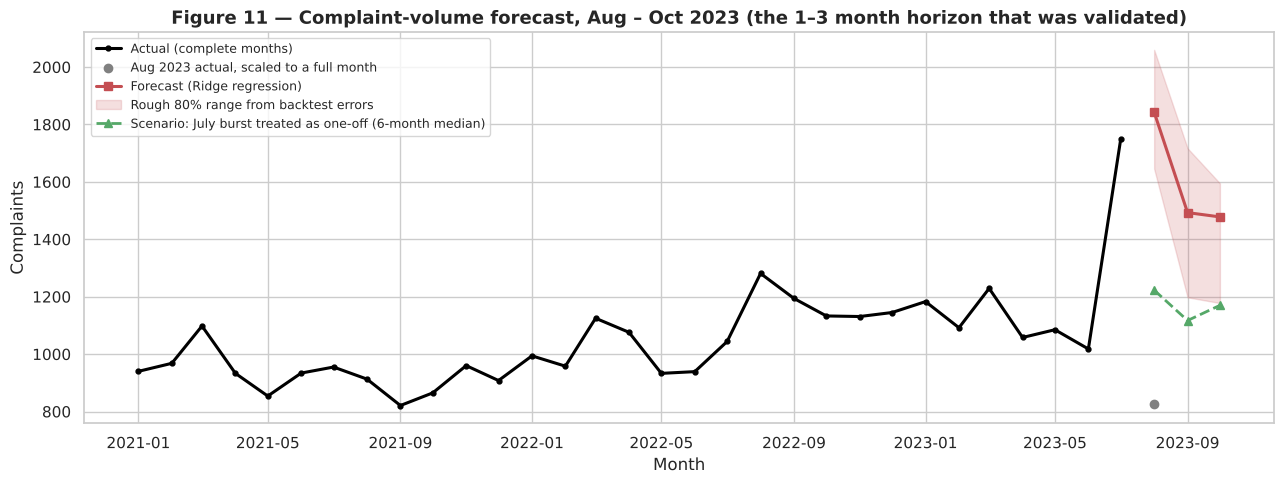

In [37]:
fig, ax = plt.subplots(figsize=(13, 5))
hist = series["2021-01":].copy(); hist.index = hist.index.to_timestamp()
ax.plot(hist.index, hist.values, color="black", lw=2.2, marker="o", ms=3.5, label="Actual (complete months)")
ax.scatter([pd.Timestamp("2023-08-01")], [actual_part * full / covered], color="grey", zorder=5, label="Aug 2023 actual, scaled to a full month")
fx = pd.to_datetime(future.month + "-01")
ax.plot(fx, future.forecast, color=PAL[3], marker="s", lw=2.2, label=f"Forecast ({best_model})")
ax.fill_between(fx, future.low_80, future.high_80, color=PAL[3], alpha=.18, label="Rough 80% range from backtest errors")
ax.plot(fx, future.robust_level_scenario, color=PAL[2], marker="^", lw=2, ls="--", label="Scenario: July burst treated as one-off (6-month median)")
ax.set_title("Figure 11 — Complaint-volume forecast, Aug – Oct 2023 (the 1–3 month horizon that was validated)")
ax.set_xlabel("Month"); ax.set_ylabel("Complaints"); ax.legend(loc="upper left", fontsize=9)
save_fig("11_future_forecast.png")

**How to read this.** The as-is model forecasts **1,843 complaints for August 2023 (full-month equivalent)** and about 1,490 for September and October. This path is pulled upward by July's burst; Section 6.4 shows that August actually came in far lower. If July is treated as a one-off, the robust-level scenario is about **1,120 – 1,220 a month**. A sensible planning range for September – October is therefore roughly **1,100 to 1,500 complaints**, to be revised each month as new data arrive. Both lines forecast **complaint volume**, not misconduct or company performance.

---
## 9. Save the workflow
Everything needed to reproduce the forecasts is saved: the monthly table, backtest forecasts, future forecasts, metrics, and the selected model's training recipe. `src/train_and_forecast.py` re-runs the final model from the raw workbook.

In [38]:
monthly_out = monthly.rename_axis("month").reset_index(); monthly_out["month"] = monthly_out.month.astype(str)
monthly_out.to_csv(OUT / "monthly_complaints.csv", index=False)
pm.rename_axis("month").reset_index().assign(month=lambda d: d.month.astype(str)).to_csv(OUT / "monthly_complaints_by_product.csv", index=False)
bt_out = pd.concat([bt_val.assign(period="validation"), bt_test.assign(period="test")]); bt_out["target"] = bt_out.target.astype(str)
bt_out.to_csv(OUT / "backtest_forecasts.csv", index=False)
future.to_csv(OUT / "future_forecast.csv", index=False)
pd.concat([m_val.assign(period="validation"), m_test.assign(period="test")]).to_csv(OUT / "backtest_metrics.csv", index=False)

# store the selected model's recipe (the models are re-fitted at every origin, so the 'model' is the recipe + data)
recipe = {"selected_model": best_model, "target": "complaints per calendar month (by Date submitted), modelled as complaints per weekday",
          "ridge_alpha": RIDGE_ALPHA, "gbm_depth": g_depth, "gbm_trees": g_trees, "arima_grid_pq": ARIMA_GRID, "arima_d": 1,
          "training_window": [str(series.index.min()), str(series.index.max())], "validation_months": [str(VAL[0]), str(VAL[-1])],
          "test_months": [str(TEST[0]), str(TEST[-1])], "interval_ratio_quantiles": q.round(4).to_dict(), "seed": SEED}
json.dump(recipe, open(MOD / "model_recipe.json", "w"), indent=2, default=str)
joblib.dump({"recipe": recipe, "series": series, "weekdays": WD, "future_forecast": future}, MOD / "complaint_forecaster.joblib")

# headline numbers for the reports
def pick(m_, name, h=None): 
    x = m_[m_.model == name]; x = x[x.horizon.isin([1, 2, 3])] if h is None else x[x.horizon == h]; return x
results["headline"] = {n: {"val_WAPE": round(float(pick(m_val, n).WAPE.mean() * 100), 1), "test_WAPE": round(float(pick(m_test, n).WAPE.mean() * 100), 1),
                           "test_ex_jul_WAPE": round(float(pick(metrics(bt_test_ex), n).WAPE.mean() * 100), 1),
                           "val_MAE": round(float(pick(m_val, n).MAE.mean()), 1), "test_MAE": round(float(pick(m_test, n).MAE.mean()), 1)} for n in MODELS}
results["h1"] = {n: {"val_WAPE": round(float(pick(m_val, n, 1).WAPE.mean() * 100), 1), "test_WAPE": round(float(pick(m_test, n, 1).WAPE.mean() * 100), 1)} for n in MODELS}
json.dump(results, open(REP / "results.json", "w"), indent=2, default=str)
print("saved:", sorted(p.name for p in list(OUT.glob("*")) + list(MOD.glob("*"))))

saved: ['backtest_forecasts.csv', 'backtest_metrics.csv', 'complaint_forecaster.joblib', 'forecast_from_script.csv', 'future_forecast.csv', 'model_recipe.json', 'monthly_complaints.csv', 'monthly_complaints_by_product.csv']


## 10. Limitations, practical implications and recommendations
**Limitations**
* **Short history.** 75 monthly points, with a trend, a dip (late 2018) and a burst (July 2023) whose causes are not in the data. Models cannot learn events they have not seen.
* **Selection did not generalise.** The validation winner (Ridge) lost to Naive on the test months. Method differences are small and not statistically significant, so no strong claim of superiority is made.
* **Only complaint counts are used.** No external drivers (outages, product changes, regulatory news, economic conditions) are available, and none are assumed.
* **Interval estimates are rough** (about 19 backtest months per horizon), and forecasts beyond 3 months were not shown to be reliable.
* **The July 2023 burst** dominates the test error. It is kept in the data because it really happened, but it makes the headline test numbers pessimistic for ordinary months.
* **Complaints are not misconduct.** The forecast describes how many complaints the CFPB will receive, not whether the company performed well or badly.

**Practical implications and recommendations**
1. **Use the forecast as a planning range, not a point estimate**, and refresh it monthly with the newest complete month.
2. **Keep a simple baseline in the loop.** Track the forecast's error against "repeat last month" every month; promote a more complex method only if it keeps winning.
3. **Monitor daily counts for bursts** (for example, more than twice the usual weekday level) and flag them, so a one-off is not carried forward automatically.
4. **Forecast only the larger products** (checking/savings, credit/prepaid card, credit reporting) where counts are high enough to be stable.
5. **Next steps:** add external event indicators if stakeholders can supply them, test a multi-year model once more history exists, and compare forecast intervals against actual coverage.